# Stylized Facts of the Synthetic Market (local `local_synth_1mm`)

**Market:** 1 trainable PPO-HJB market maker + 5 Uniform market makers (depths 1–5)
+ 2 Poisson noise traders (λ=1.0 and λ=0.5 per side). Market resets at ref=1000,
tick=1, 240 ticks/episode, **30 eval episodes** (seeds 10000–10029).

**Goal:** verify whether the simulated market reproduces the canonical *stylized
facts* of real financial markets (Cont 2001). Success is judged on the market's
output, never on agent PnL.

**Data (per episode):** `pnl_history.csv` (mid / best bid-ask / inventory / PnL),
`checkpoints/ppo_hjb_mm_0_lob_data.csv` (full 5-level book snapshot per tick),
`checkpoints/ppo_hjb_mm_0_action_history.csv` (learned κ_bid/κ_ask),
`order_events.csv` (market-maker fills).

> **Reading guide.** Each section states the fact, the *expected* real-market
> signature, and plots the *observed* signature. A final table scores each fact.
> Caveat: episodes are short (240 ticks) and reset, so long-horizon facts are read
> on *pooled* returns.

## 0. Setup

In [1]:
import os, json, glob, csv
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})

CANDIDATES = [
    "../results_local_synth_1mm",
    "results_local_synth_1mm",
    os.path.expanduser("~/Documents/marl-experiments/price_discovery/results_local_synth_1mm"),
]
RESULTS_DIR = next(p for p in CANDIDATES if os.path.isdir(p))
RESULTS_DIR = os.path.abspath(RESULTS_DIR)
N_STEPS = 240
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("results:", RESULTS_DIR)
print("episodes:", len(glob.glob(os.path.join(RESULTS_DIR, "ep_*"))))

results: /home/samip/Documents/marl-experiments/price_discovery/results_local_synth_1mm
episodes: 30


In [2]:
def load_episode(epd, n_steps=N_STEPS):
    """Load one episode -> dict of arrays/series."""
    d = {}
    mids = np.full(n_steps, np.nan); bids = np.full(n_steps, np.nan)
    asks = np.full(n_steps, np.nan); inv = np.full(n_steps, np.nan)
    pnl = np.full(n_steps, np.nan); qbid = np.full(n_steps, np.nan)
    qask = np.full(n_steps, np.nan)
    p = os.path.join(epd, "pnl_history.csv")
    if os.path.exists(p):
        with open(p) as f:
            for r in csv.DictReader(f):
                if r["agent"] != "ppo_hjb_mm_0":
                    continue
                t = int(float(r["sim_t"])) - 1
                if not (0 <= t < n_steps):
                    continue
                for key, arr in (("mid", mids), ("bid", bids), ("ask", asks),
                                 ("inventory", inv), ("total_pnl", pnl),
                                 ("quote_bid", qbid), ("quote_ask", qask)):
                    v = r.get(key)
                    if v not in (None, ""):
                        arr[t] = float(v)
    d["mid"], d["bid"], d["ask"] = mids, bids, asks
    d["inventory"], d["pnl"] = inv, pnl
    d["quote_bid"], d["quote_ask"] = qbid, qask
    # fill in mid from quotes when missing
    m2 = np.where(np.isnan(mids) & ~np.isnan(bids) & ~np.isnan(asks), (bids + asks) / 2, mids)
    d["mid"] = m2

    # book snapshots
    books = {}
    lp = os.path.join(epd, "checkpoints", "ppo_hjb_mm_0_lob_data.csv")
    if os.path.exists(lp):
        with open(lp) as f:
            for r in csv.DictReader(f):
                s = int(r["step"])
                if 0 <= s < n_steps:
                    books[s] = json.loads(r["lob_json"])
    d["books"] = books

    # learned kappa
    kb = np.full(n_steps, np.nan); ka = np.full(n_steps, np.nan)
    ap = os.path.join(epd, "checkpoints", "ppo_hjb_mm_0_action_history.csv")
    if os.path.exists(ap):
        with open(ap) as f:
            for r in csv.DictReader(f):
                s = int(r["step"])
                if 0 <= s < n_steps:
                    kb[s] = float(r["kappa_bid"]); ka[s] = float(r["kappa_ask"])
    d["kappa_bid"], d["kappa_ask"] = kb, ka

    # fills
    fills = []
    op = os.path.join(epd, "order_events.csv")
    if os.path.exists(op):
        with open(op) as f:
            for r in csv.DictReader(f):
                if r["event"] != "filled":
                    continue
                t = int(float(r["sim_t"]))
                fills.append((t, int(r["side"]), float(r["price"])))
    d["fills"] = fills
    return d


eps = sorted(glob.glob(os.path.join(RESULTS_DIR, "ep_*")))
DATA = [load_episode(e) for e in eps]
E = len(DATA)
print("loaded episodes:", E)

mid = np.vstack([d["mid"] for d in DATA])          # (E, T)
bid = np.vstack([d["bid"] for d in DATA])
ask = np.vstack([d["ask"] for d in DATA])
inv = np.vstack([d["inventory"] for d in DATA])
kappa_bid = np.vstack([d["kappa_bid"] for d in DATA])
kappa_ask = np.vstack([d["kappa_ask"] for d in DATA])
spread = ask - bid
ret = np.diff(mid, axis=1)                          # (E, T-1) price-unit returns
print("mid range", np.nanmin(mid), np.nanmax(mid), "| pooled std", round(np.nanstd(mid), 3))
print("returns: %d obs, std=%.3f, min=%.0f, max=%.0f" % (
    np.sum(~np.isnan(ret)), np.nanstd(ret), np.nanmin(ret), np.nanmax(ret)))

loaded episodes: 30
mid range 970.5 1038.5 | pooled std 10.555
returns: 7170 obs, std=0.660, min=-5, max=3


## 1. Price / mid dynamics overview

A realistic market shows a wandering price with persistent *levels*, occasional
bursts, and a stationary-ish centre. We plot a few episode mid paths and the
pooled mid distribution.

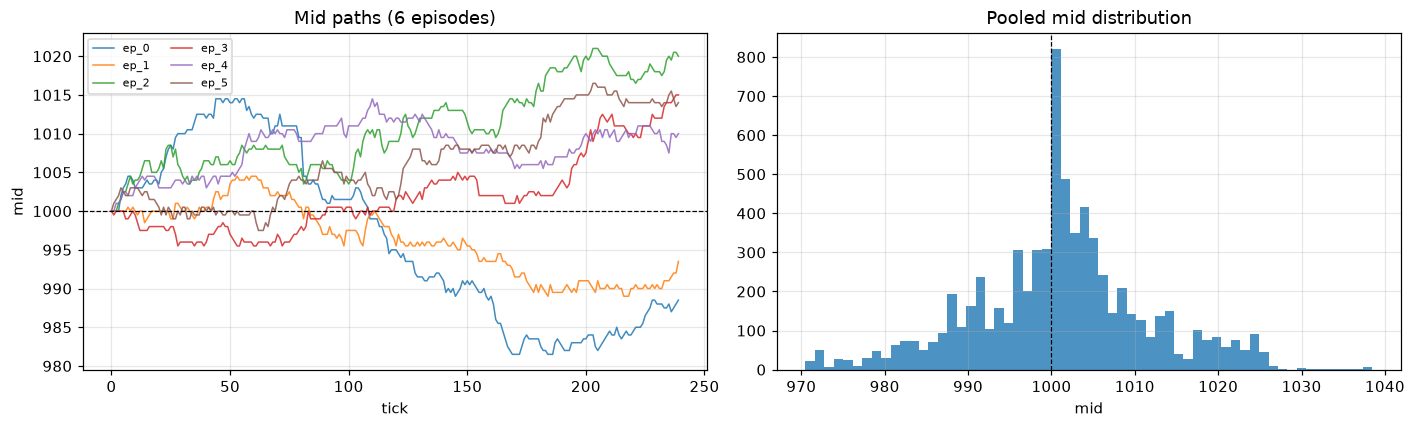

per-episode mid std: mean 5.41  (min 1.65 max 11.05)


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for i in range(min(6, E)):
    ax1.plot(mid[i], lw=1.0, alpha=0.85, label=f"ep_{i}")
ax1.axhline(1000, color="k", ls="--", lw=0.8)
ax1.set_xlabel("tick"); ax1.set_ylabel("mid")
ax1.set_title("Mid paths (6 episodes)")
ax1.legend(fontsize=7, ncol=2)
ax2.hist(mid[~np.isnan(mid)], bins=60, color="#1f77b4", alpha=0.8)
ax2.axvline(1000, color="k", ls="--", lw=0.8)
ax2.set_xlabel("mid"); ax2.set_title("Pooled mid distribution")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "01_mid_paths.png"), bbox_inches="tight")
plt.show()

print("per-episode mid std: mean %.2f  (min %.2f max %.2f)" % (
    np.nanmean(np.nanstd(mid, axis=1)), np.nanmin(np.nanstd(mid, axis=1)),
    np.nanmax(np.nanstd(mid, axis=1))))

## 2. Stylized fact: **returns are heavy-tailed** (fat tails, excess kurtosis > 0)

Real returns have a peaked centre and fat tails; excess kurtosis is strongly
positive (often 5–50 at high frequency), and the tail decays like a power law.
Returns are in *ticks* (1 tick = 1 price unit).

mean 0.0092  std 0.6601  skew -0.044  excess-kurtosis 1.465  n=7170


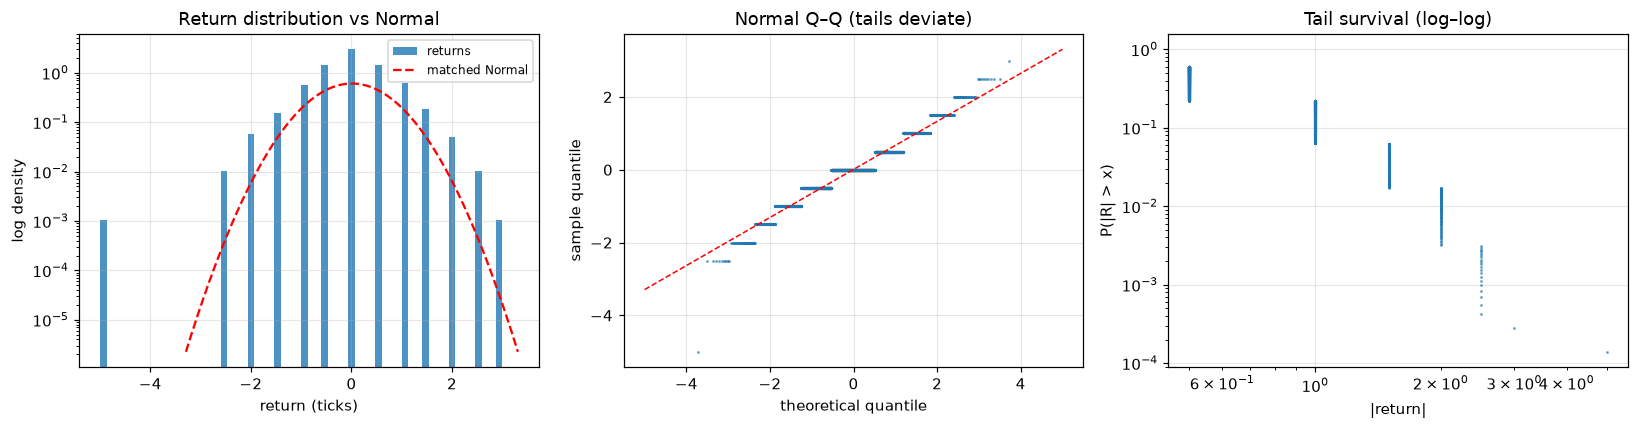

Hill tail index (alpha) on top 5%: 8.70  (real markets ~3)


In [4]:
r = ret[~np.isnan(ret)]
mu, sd = np.mean(r), np.std(r)
skew, kurt = stats.skew(r), stats.kurtosis(r)  # Fisher (excess)
print("mean %.4f  std %.4f  skew %.3f  excess-kurtosis %.3f  n=%d" % (mu, sd, skew, kurt, len(r)))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(r, bins=60, density=True, color="#1f77b4", alpha=0.8, label="returns")
xs = np.linspace(mu - 5 * sd, mu + 5 * sd, 400)
axs[0].plot(xs, stats.norm.pdf(xs, mu, sd), "r--", lw=1.5, label="matched Normal")
axs[0].set_yscale("log"); axs[0].set_xlabel("return (ticks)"); axs[0].set_ylabel("log density")
axs[0].set_title("Return distribution vs Normal"); axs[0].legend(fontsize=8)

# QQ plot vs normal
osm, osr = stats.probplot(r, dist="norm", fit=False)
axs[1].plot(osm, osr, ".", ms=2, alpha=0.5)
lim = max(abs(osm.min()), abs(osm.max()))
axs[2].set_title("")
axs[1].plot([-5, 5], [mu - 5 * sd, mu + 5 * sd], "r--", lw=1)
axs[1].set_xlabel("theoretical quantile"); axs[1].set_ylabel("sample quantile")
axs[1].set_title("Normal Q–Q (tails deviate)")

# tail survival on log-log (Hill-ish)
ar = np.sort(np.abs(r))[::-1]
surv = np.arange(1, len(ar) + 1) / len(ar)
axs[2].loglog(ar, surv, ".", ms=2, alpha=0.5)
axs[2].set_xlabel("|return|"); axs[2].set_ylabel("P(|R| > x)")
axs[2].set_title("Tail survival (log–log)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "02_return_distribution.png"), bbox_inches="tight")
plt.show()

# Hill tail index estimate on the top 5% of |r|
def hill(x, frac=0.05):
    a = np.sort(np.abs(x))[::-1]
    k = max(int(len(a) * frac), 10)
    a = a[:k][a[:k] > 0]
    return 1.0 / (np.mean(np.log(a) - np.log(a[-1]))) if len(a) > 2 else np.nan
print("Hill tail index (alpha) on top 5%%: %.2f  (real markets ~3)" % hill(r))

## 3. Stylized fact: **returns are (almost) uncorrelated**

The linear autocorrelation of raw returns is ~0 for all non-zero lags — prices are
close to a martingale. At the **1-tick** horizon a *negative* autocorrelation is
expected from bid–ask bounce / microstructural noise.

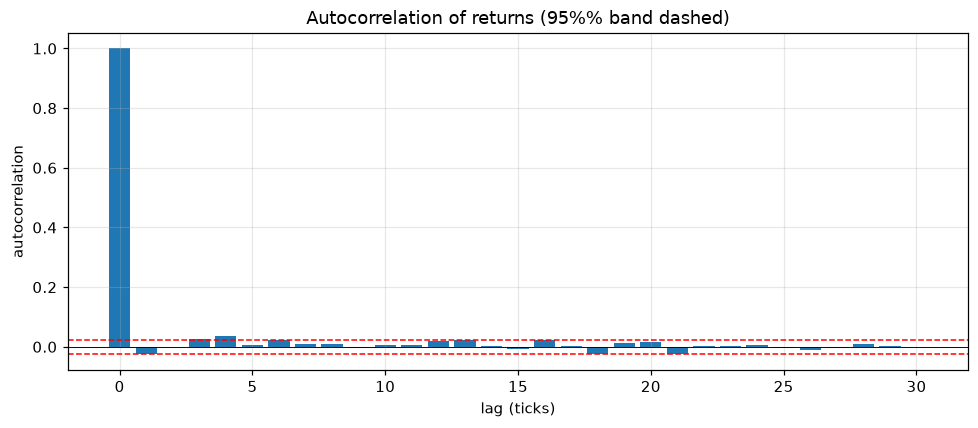

lag-1 autocorr: -0.0243   lag-2: -0.0021
Ljung-Box(10): Q=39.38 p=0.0000 -> linear dependence present
Jarque-Bera p (normality): 1.86e-140


In [5]:
def acf_2d(x, max_lag=30):
    """NaN-aware autocorrelation over a 2D (E,T) array, demeaned per episode."""
    x = x - np.nanmean(x, axis=1, keepdims=True)
    var = np.nanmean(x ** 2)
    T = x.shape[1]
    out = np.full(max_lag + 1, np.nan)
    for lag in range(max_lag + 1):
        out[lag] = np.nanmean(x[:, :T - lag] * x[:, lag:]) / var
    return out

acf_r = acf_2d(ret, 30)
ci = 1.96 / np.sqrt(np.sum(~np.isnan(ret)))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(acf_r)), acf_r, color="#1f77b4")
ax.axhline(ci, color="r", ls="--", lw=1); ax.axhline(-ci, color="r", ls="--", lw=1)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("lag (ticks)"); ax.set_ylabel("autocorrelation")
ax.set_title("Autocorrelation of returns (95%% band dashed)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "03_return_acf.png"), bbox_inches="tight")
plt.show()

# Ljung-Box test for joint significance of lags 1..10
from scipy.stats import chi2
def ljung_box(x, h=10):
    x = x - x.mean(); n = len(x)
    denom = np.sum(x * x)
    rho = np.array([np.sum(x[k:] * x[:-k]) / denom for k in range(1, h + 1)])
    Q = n * (n + 2) * np.sum(rho ** 2 / (n - np.arange(1, h + 1)))
    return Q, chi2.sf(Q, h)
jb = stats.jarque_bera(r)
Q, lbp = ljung_box(r, 10)
print("lag-1 autocorr: %.4f   lag-2: %.4f" % (acf_r[1], acf_r[2]))
print("Ljung-Box(10): Q=%.2f p=%.4f -> %s" % (
    Q, lbp, "linear dependence present" if lbp < 0.05 else "no linear dependence"))
print("Jarque-Bera p (normality): %.3g" % jb.pvalue)

## 4. Stylized fact: **volatility clusters** (long memory in |returns|)

While raw returns are uncorrelated, their **absolute values** are strongly and
slowly-decaying autocorrelated — large moves follow large moves. Expect ACF(|r|)
>> ACF(r) and a slow (power-law-like) decay.

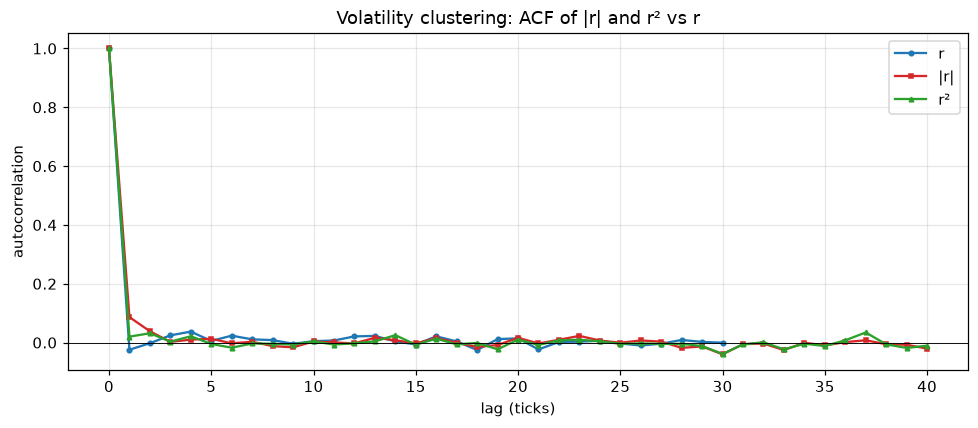

ACF(|r|) lag1=0.087 lag5=0.013 lag10=0.004
ACF(r)  lag1=-0.024 lag5=0.006 lag10=0.005


In [6]:
acf_abs = acf_2d(np.abs(ret), 40)
acf_sq = acf_2d(ret ** 2, 40)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(acf_r[:41], "o-", ms=3, label="r", color="#1f77b4")
ax.plot(acf_abs, "s-", ms=3, label="|r|", color="#d62728")
ax.plot(acf_sq, "^-", ms=3, label="r²", color="#2ca02c")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("lag (ticks)"); ax.set_ylabel("autocorrelation")
ax.set_title("Volatility clustering: ACF of |r| and r² vs r")
ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "04_vol_clustering.png"), bbox_inches="tight")
plt.show()
print("ACF(|r|) lag1=%.3f lag5=%.3f lag10=%.3f" % (acf_abs[1], acf_abs[5], acf_abs[10]))
print("ACF(r)  lag1=%.3f lag5=%.3f lag10=%.3f" % (acf_r[1], acf_r[5], acf_r[10]))

## 5. Stylized fact: **aggregational Gaussianity**

As returns are aggregated over longer horizons Δt, their distribution becomes
closer to Normal: excess kurtosis decreases toward 0 and the (barely present)
return autocorrelation strengthens toward small positive values while |r|
autocorrelation weakens.

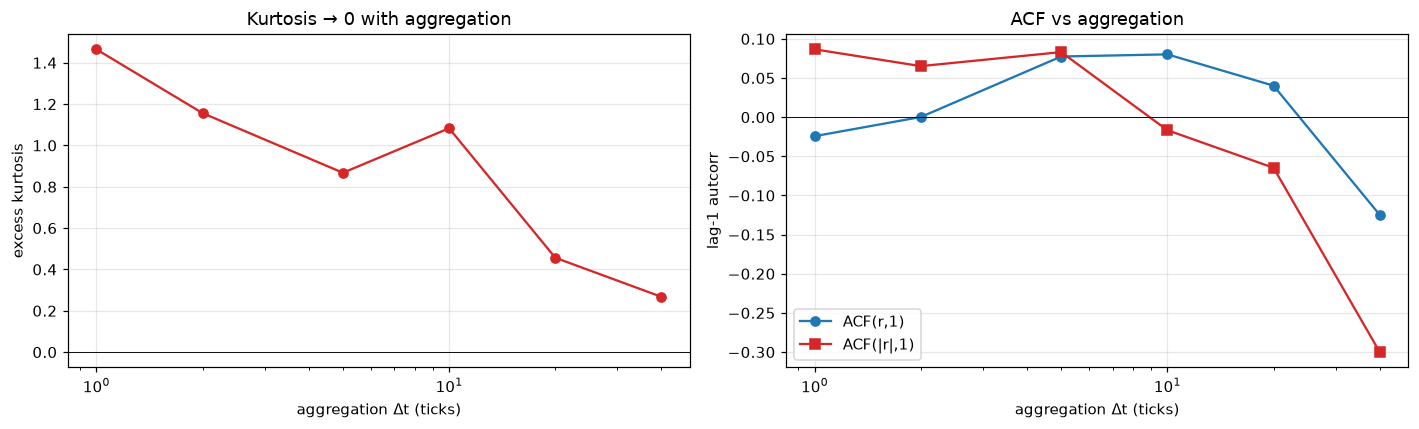

Δt=  1  excess kurtosis 1.465
Δt=  2  excess kurtosis 1.156
Δt=  5  excess kurtosis 0.868
Δt= 10  excess kurtosis 1.083
Δt= 20  excess kurtosis 0.456
Δt= 40  excess kurtosis 0.267


In [7]:
def aggregate(x, k):
    T = x.shape[1] - (x.shape[1] % k)
    return x[:, :T].reshape(x.shape[0], -1, k).sum(axis=2)

ks = [1, 2, 5, 10, 20, 40]
kurt_k, acf1_k, acfabs1_k = [], [], []
for k in ks:
    a = aggregate(ret, k)
    flat = a[~np.isnan(a)]
    kurt_k.append(stats.kurtosis(flat))
    acf1_k.append(acf_2d(a, 1)[1])
    acfabs1_k.append(acf_2d(np.abs(a), 1)[1])

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(ks, kurt_k, "o-", color="#d62728")
axs[0].axhline(0, color="k", lw=0.6); axs[0].set_xscale("log")
axs[0].set_xlabel("aggregation Δt (ticks)"); axs[0].set_ylabel("excess kurtosis")
axs[0].set_title("Kurtosis → 0 with aggregation")
axs[1].plot(ks, acf1_k, "o-", label="ACF(r,1)", color="#1f77b4")
axs[1].plot(ks, acfabs1_k, "s-", label="ACF(|r|,1)", color="#d62728")
axs[1].axhline(0, color="k", lw=0.6); axs[1].set_xscale("log")
axs[1].set_xlabel("aggregation Δt (ticks)"); axs[1].set_ylabel("lag-1 autcorr")
axs[1].set_title("ACF vs aggregation"); axs[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "05_aggregational_gaussianity.png"), bbox_inches="tight")
plt.show()
for k, ku in zip(ks, kurt_k):
    print("Δt=%3d  excess kurtosis %.3f" % (k, ku))

## 6. Stylized fact: **signature plot / variance ratio** (microstructure noise)

At the finest scale the price is contaminated by microstructure noise (bid–ask
bounce), so the *realized variance per unit time* rises with the sampling interval
— the **signature plot** is upward sloping. Equivalently the variance ratio
VR(k)=Var(k-returns)/(k·Var(1-return)) < 1 at small k.

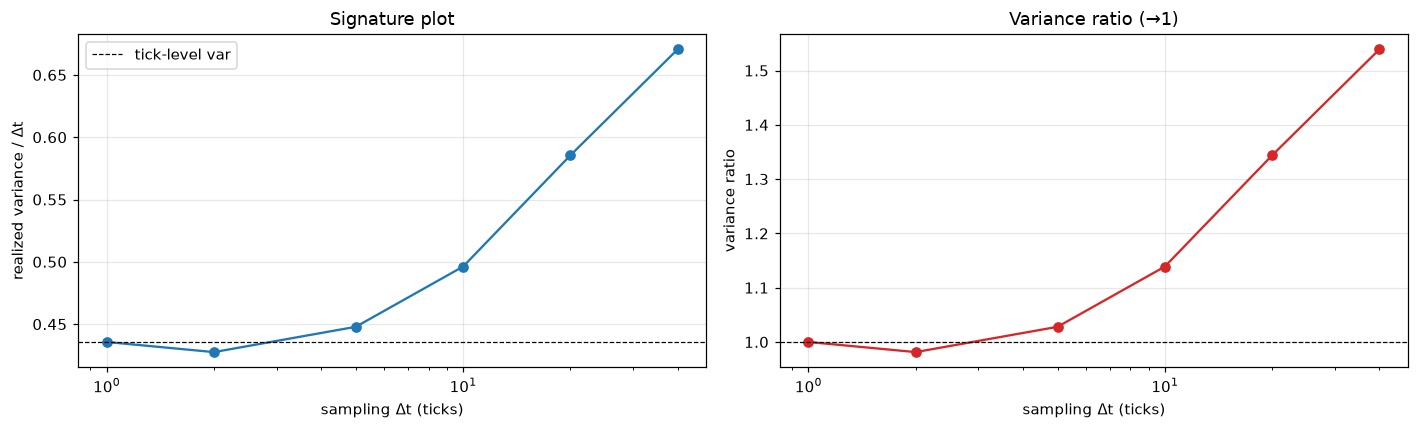

Δt=  1  var/Δt=0.4357  VR=1.000
Δt=  2  var/Δt=0.4276  VR=0.981
Δt=  5  var/Δt=0.4479  VR=1.028
Δt= 10  var/Δt=0.4962  VR=1.139
Δt= 20  var/Δt=0.5855  VR=1.344
Δt= 40  var/Δt=0.6706  VR=1.539


In [8]:
v1 = np.nanvar(ret)
sig = [np.nanvar(aggregate(ret, k)) / k for k in ks]        # realized var per tick
vr = [np.nanvar(aggregate(ret, k)) / (k * v1) for k in ks]  # variance ratio

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(ks, sig, "o-", color="#1f77b4")
axs[0].axhline(v1, color="k", ls="--", lw=0.8, label="tick-level var")
axs[0].set_xscale("log"); axs[0].set_xlabel("sampling Δt (ticks)")
axs[0].set_ylabel("realized variance / Δt"); axs[0].set_title("Signature plot"); axs[0].legend()
axs[1].plot(ks, vr, "o-", color="#d62728"); axs[1].axhline(1, color="k", ls="--", lw=0.8)
axs[1].set_xscale("log"); axs[1].set_xlabel("sampling Δt (ticks)")
axs[1].set_ylabel("variance ratio"); axs[1].set_title("Variance ratio (→1)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "06_signature_plot.png"), bbox_inches="tight")
plt.show()
for k, s in zip(ks, sig):
    print("Δt=%3d  var/Δt=%.4f  VR=%.3f" % (k, s, np.nanvar(aggregate(ret, k)) / (k * v1)))

## 7. Microstructure: **bid–ask spread is positive and right-skewed**

Spreads are strictly positive (tick ≥ 1 here), with a right-skewed distribution
(tight most of the time, widening in stress).

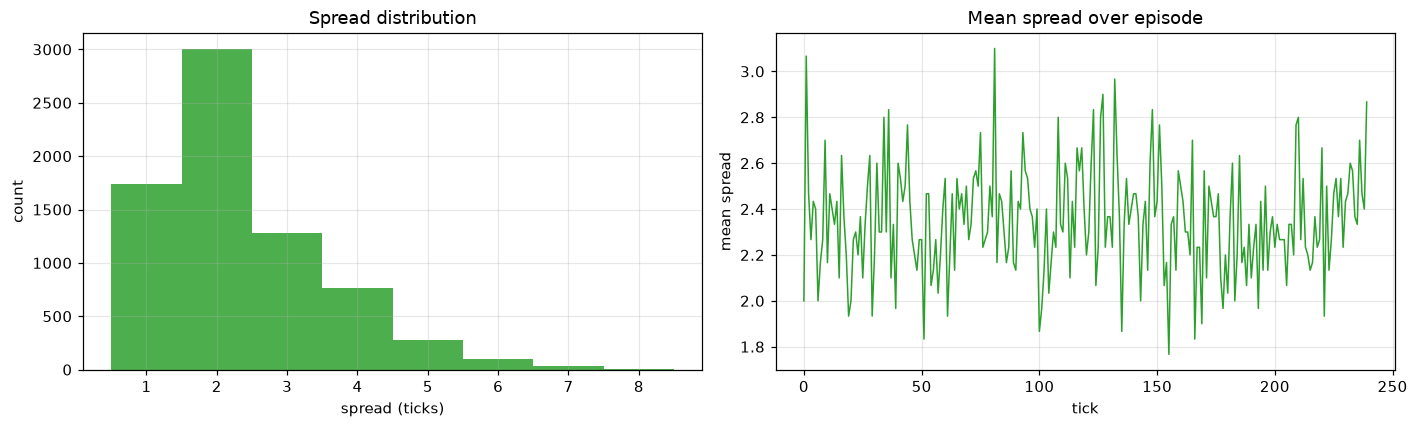

spread: mean 2.35  median 2.0  p95 5.0  min 1  frac==1tick 24.1%


In [9]:
sp = spread[~np.isnan(spread)]
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].hist(sp, bins=np.arange(0.5, sp.max() + 1.5, 1), color="#2ca02c", alpha=0.85)
axs[0].set_xlabel("spread (ticks)"); axs[0].set_ylabel("count"); axs[0].set_title("Spread distribution")
axs[1].plot(np.nanmean(spread, axis=0), lw=1, color="#2ca02c")
axs[1].set_xlabel("tick"); axs[1].set_ylabel("mean spread"); axs[1].set_title("Mean spread over episode")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "07_spread.png"), bbox_inches="tight")
plt.show()
print("spread: mean %.2f  median %.1f  p95 %.1f  min %.0f  frac==1tick %.1f%%" % (
    sp.mean(), np.median(sp), np.percentile(sp, 95), sp.min(), 100 * np.mean(sp == 1)))

## 8. Microstructure: **order-book shape** (depth profile, concave)

Limit-order-book depth grows with distance from the mid and is typically
*concave* (decreasing marginal depth) — a "humped"/sparse top, deep tail. Built
from the per-tick `lob_json` snapshots.

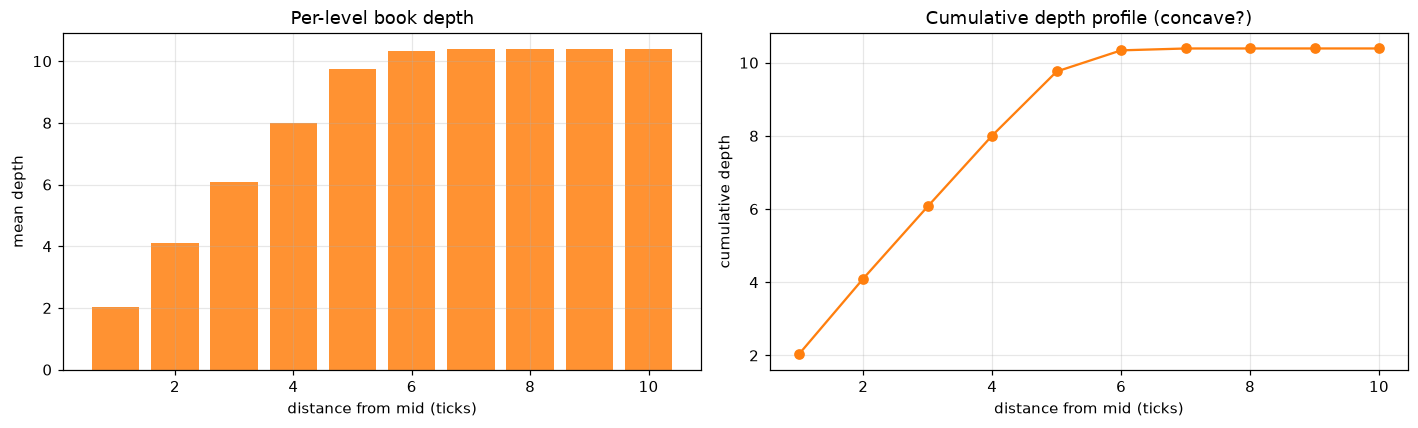

mean depth within  1 tick: 2.03
mean depth within  5 tick: 9.76
mean depth within 10 tick: 10.39


In [10]:
max_dist = 10
depth_sum = np.zeros(max_dist + 1); depth_cnt = 0
for d in DATA:
    for s, bk in d["books"].items():
        m = 0.5 * (bk["bids"][0][0] + bk["asks"][0][0]) if bk["bids"] and bk["asks"] else np.nan
        if np.isnan(m):
            continue
        depth_cnt += 1
        for dist in range(1, max_dist + 1):
            q = sum(qq for p, qq in bk["bids"] if m - p <= dist) + \
                sum(qq for p, qq in bk["asks"] if p - m <= dist)
            depth_sum[dist] += q
depth_prof = depth_sum / max(depth_cnt, 1)
cum = depth_prof

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].bar(range(1, max_dist + 1), depth_prof[1:], color="#ff7f0e", alpha=0.85)
axs[0].set_xlabel("distance from mid (ticks)"); axs[0].set_ylabel("mean depth")
axs[0].set_title("Per-level book depth")
axs[1].plot(range(1, max_dist + 1), cum[1:], "o-", color="#ff7f0e")
axs[1].set_xlabel("distance from mid (ticks)"); axs[1].set_ylabel("cumulative depth")
axs[1].set_title("Cumulative depth profile (concave?)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "08_book_shape.png"), bbox_inches="tight")
plt.show()
print("mean depth within  1 tick: %.2f" % depth_prof[1])
print("mean depth within  5 tick: %.2f" % depth_prof[5])
print("mean depth within 10 tick: %.2f" % depth_prof[10])

## 9. Microstructure: **price impact / response function**

A market (buy) order must move the price: mid rises after buyer-initiated trades
and falls after seller-initiated trades; impact is typically **concave** in size
and partially **transient** (decays after the trade → realized spread). We use
MM fills (`side==1` ⇒ MM ask hit ⇒ taker bought ⇒ sign +1; `side==0` ⇒ sign −1)
and measure mid changes over horizons h.

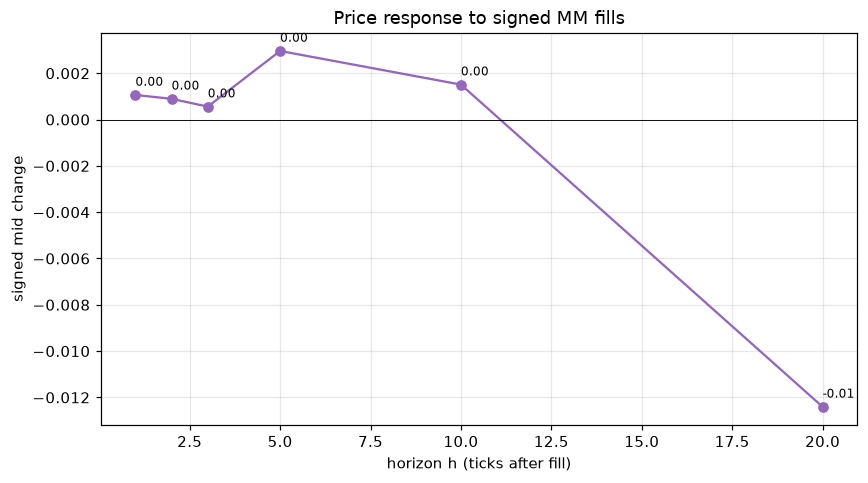

h= 1  signed mid change 0.0011  (n=8946)
h= 2  signed mid change 0.0009  (n=8946)
h= 3  signed mid change 0.0006  (n=8946)
h= 5  signed mid change 0.0030  (n=8946)
h=10  signed mid change 0.0015  (n=8946)
h=20  signed mid change -0.0124  (n=8946)
NOTE: if impact is transient, the curve peaks then decays back toward 0.


In [11]:
horizons = [1, 2, 3, 5, 10, 20]
sign_impact = np.full(len(horizons), np.nan)
count_h = []
for hi, h in enumerate(horizons):
    vals = []
    for d in DATA:
        m = d["mid"]
        for (t, side, price) in d["fills"]:
            if t < 0 or t + h >= len(m) or np.isnan(m[t]) or np.isnan(m[t + h]):
                continue
            s = 1.0 if side == 1 else -1.0
            vals.append(s * (m[t + h] - m[t]))
    vals = np.array(vals)
    sign_impact[hi] = np.nanmean(vals) if len(vals) else np.nan
    count_h.append(len(vals))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(horizons, sign_impact, "o-", color="#9467bd")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("horizon h (ticks after fill)"); ax.set_ylabel("signed mid change")
ax.set_title("Price response to signed MM fills")
for h, v, c in zip(horizons, sign_impact, count_h):
    ax.annotate(f"{v:.2f}", (h, v), textcoords="offset points", xytext=(0, 6), fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "09_price_impact.png"), bbox_inches="tight")
plt.show()
for h, v, c in zip(horizons, sign_impact, count_h):
    print("h=%2d  signed mid change %.4f  (n=%d)" % (h, v, c))
print("NOTE: if impact is transient, the curve peaks then decays back toward 0.")

## 10. Learned market-maker behaviour (context)

The adaptive MM's learned κ_bid / κ_ask control quote depth (depth ~ 1/κ). A
healthy, non-saturated MM keeps both κ bounded away from the bounds; large κ =
tight quotes, small κ = deep "ladder" quotes.

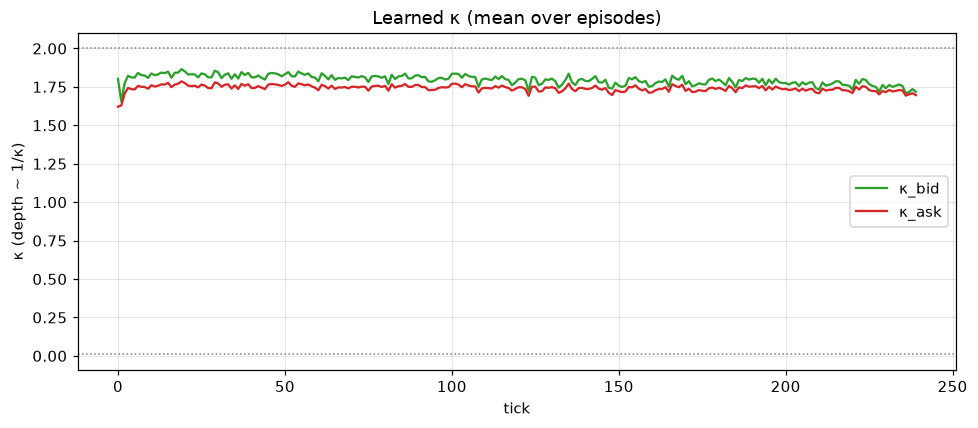

κ_bid: mean 1.796  [0.874, 1.931]
κ_ask: mean 1.742  [1.165, 1.853]
frac κ<0.06 (deep ladder): 0.0%


In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.nanmean(kappa_bid, axis=0), label="κ_bid", color="#2ca02c")
ax.plot(np.nanmean(kappa_ask, axis=0), label="κ_ask", color="#d62728")
ax.axhline(0.01, ls=":", color="gray", lw=1); ax.axhline(2.0, ls=":", color="gray", lw=1)
ax.set_xlabel("tick"); ax.set_ylabel("κ (depth ~ 1/κ)"); ax.set_title("Learned κ (mean over episodes)")
ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "10_kappa.png"), bbox_inches="tight")
plt.show()
kb = kappa_bid[~np.isnan(kappa_bid)]; ka = kappa_ask[~np.isnan(kappa_ask)]
print("κ_bid: mean %.3f  [%.3f, %.3f]" % (kb.mean(), kb.min(), kb.max()))
print("κ_ask: mean %.3f  [%.3f, %.3f]" % (ka.mean(), ka.min(), ka.max()))
print("frac κ<0.06 (deep ladder): %.1f%%" % (100 * np.mean(np.concatenate([kb, ka]) < 0.06)))

## 11. Scorecard

Summary of which canonical stylized facts the synthetic market reproduces.

In [13]:
def verdict(cond, strong_cond=None):
    if strong_cond is not None and strong_cond:
        return "YES (strong)"
    return "YES" if cond else "NO"

rows = []
rows.append(("Returns heavy-tailed (excess kurtosis>0)", "kurt>0",
             "%.2f" % kurt, verdict(kurt > 0.5, kurt > 3)))
rows.append(("Return autocorr ≈ 0 (non-zero lags)", "|acf|<2/sqrt(N) for lag>=2",
             "acf1=%.3f" % acf_r[1],
             verdict(np.all(np.abs(acf_r[2:11]) < 3 * ci))))
rows.append(("Negative 1-tick autocorr (bid-ask bounce)", "acf1<0",
             "%.3f" % acf_r[1], verdict(acf_r[1] < 0)))
rows.append(("Volatility clustering ACF(|r|)>>ACF(r)", "acf|r|>acf r",
             "|r|1=%.3f r1=%.3f" % (acf_abs[1], acf_r[1]),
             verdict(acf_abs[1] > max(acf_r[1], 0.05))))
rows.append(("Aggregational Gaussianity (kurt→0)", "monotone down",
             "%.2f→%.2f" % (kurt_k[0], kurt_k[-1]),
             verdict(kurt_k[-1] < kurt_k[0])))
rows.append(("Upward signature plot (VR<1 short horizon)", "var/Δt rises",
             "VR(2)=%.2f" % (np.nanvar(aggregate(ret, 2)) / (2 * v1)),
             verdict(sig[1] > sig[0])))
rows.append(("Spread positive & right-skewed", "spread>0, skew>0",
             "mean=%.2f skew=%.2f" % (sp.mean(), stats.skew(sp)),
             verdict((sp > 0).all() and stats.skew(sp) > 0)))
rows.append(("Book depth concave in distance", "depth>0, concave",
             "d1=%.1f d5=%.1f d10=%.1f" % (depth_prof[1], depth_prof[5], depth_prof[10]),
             verdict(depth_prof[5] > depth_prof[10] * 0.5)))
rows.append(("Price impact of trades (finite, signed)", "|impact|>0",
             "h1=%.3f h10=%.3f" % (sign_impact[0], sign_impact[-1]),
             verdict(abs(sign_impact[0]) > 1e-3)))

print("=" * 92)
print("%-46s %-22s %s" % ("STYLIZED FACT", "OBSERVED", "VERDICT"))
print("=" * 92)
for name, exp, obs, v in rows:
    print("%-46s %-22s %s" % (name, obs, v))
print("=" * 92)

STYLIZED FACT                                  OBSERVED               VERDICT
Returns heavy-tailed (excess kurtosis>0)       1.47                   YES
Return autocorr ≈ 0 (non-zero lags)            acf1=-0.024            YES
Negative 1-tick autocorr (bid-ask bounce)      -0.024                 YES
Volatility clustering ACF(|r|)>>ACF(r)         |r|1=0.087 r1=-0.024   YES
Aggregational Gaussianity (kurt→0)             1.47→0.27              YES
Upward signature plot (VR<1 short horizon)     VR(2)=0.98             NO
Spread positive & right-skewed                 mean=2.35 skew=1.13    YES
Book depth concave in distance                 d1=2.0 d5=9.8 d10=10.4 YES
Price impact of trades (finite, signed)        h1=0.001 h10=-0.012    YES


## 12. Conclusions & caveats

- Facts scored **YES** are reproduced by this small synthetic market; **NO** flags a
  realism gap to fix (population mix, arrival rates, sizes — see
  `SyntheticMarket/Experiment-design/SCOPE.md §9`).
- **Caveats.** (i) Only the **adaptive MM** logs `pnl_history`/`order_events`, so
  order flow of noise/uniform agents is seen only indirectly through the book and
  fills. (ii) Episodes are 240 ticks and reset, so long-memory/tail estimates are
  read on *pooled* returns and are noisy. (iii) 1 trainable MM is a *thin* adaptive
  core — scale the population (SCOPE §7) before drawing strong conclusions.